# Week 08: Case Study - Structural Demo

**Course:** MATH7810 Python for Data Science (AY2026/27)

## 1.1 Background and general information

This file is a random sample of 2,000 passengers from an airline survey. One row is one passenger. Seat comfort, entertainment, baggage handling, cleanliness, and gate location are 1 to 5. Wifi, departure and arrival convenience, online booking, food and drink, and online boarding also include 0, which means not applicable. 

The average_service_score is the mean of on-board service, leg room, check-in, and inflight service. total_rating_score is a column added to the file. It is the sum of the items scored from 1 to 5: gate location, seat comfort, inflight entertainment, baggage handling, and cleanliness.  

The file is `airline_passenger_satisfaction.csv`, in this week folder.

| Column | Meaning |
|--------|---------|
| `id` | Identifier for the passenger. Not a measurement. |
| `Gender` | Female or Male. |
| `Customer Type` | Loyal Customer or disloyal Customer. |
| `Age` | Age in years. |
| `Type of Travel` | Business travel or Personal Travel. |
| `Class` | Business, Eco, or Eco Plus. |
| `Flight Distance` | Flight distance in miles. |
| `Inflight wifi service` | Score for inflight wifi. |
| `Departure/Arrival time convenient` | Score for how convenient the departure and arrival times are. |
| `Ease of Online booking` | Score for online booking. |
| `Gate location` | Score for the gate location. |
| `Food and drink` | Score for food and drink. |
| `Online boarding` | Score for online boarding. |
| `Seat comfort` | Score for seat comfort. |
| `Inflight entertainment` | Score for inflight entertainment. |
| `Baggage handling` | Score for baggage handling. |
| `Cleanliness` | Score for cleanliness. |
| `average_service_score` | Mean of on-board service, leg room, check-in, and inflight service. |
| `total_rating_score` | Sum of the items scored from 1 to 5: gate location, seat comfort, inflight entertainment, baggage handling, and cleanliness. Added to the file. |
| `Departure Delay in Minutes` | Minutes late at departure. |
| `Arrival Delay in Minutes` | Minutes late at arrival. Missing for some passengers. |
| `satisfaction` | satisfied, or neutral or dissatisfied. Binary variable. |

### Shape and missing values


In [1]:
import pandas as pd

# One row is one passenger.
df = pd.read_csv("airline_passenger_satisfaction.csv")

# Sum of the five items scored from 1 to 5.
# If any of the five is missing, the total is missing too.
rating_items = [
    "Gate location",
    "Seat comfort",
    "Inflight entertainment",
    "Baggage handling",
    "Cleanliness",
]
df["total_rating_score"] = df[rating_items].sum(axis=1, min_count=len(rating_items))
print("rows, columns:", df.shape)
print("missing values:")
print(df.isna().sum())


rows, columns: (2000, 22)
missing values:
id                                     0
Gender                                66
Customer Type                         38
Age                                   63
Type of Travel                        77
Class                                 56
Flight Distance                       50
Inflight wifi service                 54
Departure/Arrival time convenient     26
Ease of Online booking                22
Gate location                         47
Food and drink                        51
Online boarding                       37
Seat comfort                          55
Inflight entertainment                21
Baggage handling                      28
Cleanliness                           37
average_service_score                 32
Departure Delay in Minutes            57
Arrival Delay in Minutes              57
satisfaction                          76
total_rating_score                   181
dtype: int64


### Categorical variables


In [2]:
# Counts for each category. dropna=False keeps the missing values in the table.
categorical = ["Gender", "Customer Type", "Type of Travel", "Class", "satisfaction"]
for column in categorical:
    print(column)
    print(df[column].value_counts(dropna=False))
    print()


Gender
Gender
Male      997
Female    937
NaN        66
Name: count, dtype: int64

Customer Type
Customer Type
Loyal Customer       1623
disloyal Customer     339
NaN                    38
Name: count, dtype: int64

Type of Travel
Type of Travel
Business travel    1306
Personal Travel     617
NaN                  77
Name: count, dtype: int64

Class
Class
Business    897
Eco         882
Eco Plus    165
NaN          56
Name: count, dtype: int64

satisfaction
satisfaction
neutral or dissatisfied    1083
satisfied                   841
NaN                          76
Name: count, dtype: int64



## 1.2 Numerical descriptive statistics

Age, flight distance, average_service_score, departure delay, and arrival delay are summarised by the five-number summary: minimum, first quartile, median, third quartile, and maximum. The same quartiles are then used to flag outliers.


### Numerical variables


In [3]:
# Five-number summary of the observed values: minimum, Q1, median, Q3, maximum.
numeric = ["Age", "Flight Distance", "average_service_score", "Departure Delay in Minutes", "Arrival Delay in Minutes"]
five = df[numeric].quantile([0, 0.25, 0.5, 0.75, 1]).T
five.columns = ["Minimum", "Q1", "Median", "Q3", "Maximum"]
print(five.round(2))


                            Minimum      Q1  Median       Q3  Maximum
Age                             7.0   27.00    40.0    51.00     80.0
Flight Distance                67.0  413.25   839.5  1707.75   4243.0
average_service_score           1.0    2.75     3.5     4.00      5.0
Departure Delay in Minutes      0.0    0.00     0.0    12.00    407.0
Arrival Delay in Minutes        0.0    0.00     0.0    14.00    409.0


### Outliers

A value is an outlier when it lies below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. IQR is Q3 minus Q1. The percentage is the number of outliers divided by the number of observed values.


In [4]:
# A value is an outlier when it lies below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.
# The percentage is the number of outliers divided by the number of observed values.
outlier_rows = []
for column in numeric:
    values = df[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = int(((values < lower) | (values > upper)).sum())
    percentage = round(100 * n_out / len(values), 1)
    outlier_rows.append([column, round(lower, 2), round(upper, 2), n_out, percentage])

outliers = pd.DataFrame(
    outlier_rows,
    columns=["variable", "lower fence", "upper fence", "outliers", "percentage"],
)
print(outliers.to_string(index=False))


                  variable  lower fence  upper fence  outliers  percentage
                       Age        -9.00        87.00         0         0.0
           Flight Distance     -1528.50      3649.50        60         3.1
     average_service_score         0.88         5.88         0         0.0
Departure Delay in Minutes       -18.00        30.00       270        13.9
  Arrival Delay in Minutes       -21.00        35.00       256        13.2


## 1.3 Exploratory analysis with visualizations


### 1.3.1 Service scores


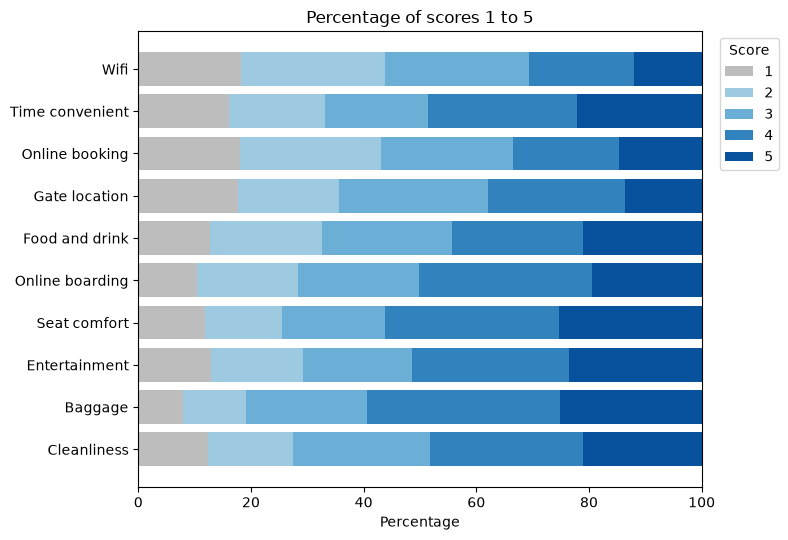

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Percentage of scores 1 to 5 for each rating.
# A score of 0 means the item did not apply, so 0 and missing values are left out.
# The segments of each bar then sum to 100%.
ratings = [
    ("Inflight wifi service", "Wifi"),
    ("Departure/Arrival time convenient", "Time convenient"),
    ("Ease of Online booking", "Online booking"),
    ("Gate location", "Gate location"),
    ("Food and drink", "Food and drink"),
    ("Online boarding", "Online boarding"),
    ("Seat comfort", "Seat comfort"),
    ("Inflight entertainment", "Entertainment"),
    ("Baggage handling", "Baggage"),
    ("Cleanliness", "Cleanliness"),
]
scores = [1, 2, 3, 4, 5]
rows = []
for column, _ in ratings:
    values = df[column].dropna()
    values = values[values.isin(scores)]
    share = values.value_counts(normalize=True).reindex(scores, fill_value=0) * 100
    rows.append(share)
table = pd.DataFrame(rows, index=[name for _, name in ratings])
colors = ["#bdbdbd", "#9ecae1", "#6baed6", "#3182bd", "#08519c"]

fig, ax = plt.subplots(figsize=(8, 5.5))
left = pd.Series(0.0, index=table.index)
for score, color in zip(scores, colors):
    ax.barh(table.index, table[score], left=left, color=color, label=str(score))
    left = left + table[score]
ax.invert_yaxis()
ax.set_xlabel("Percentage")
ax.set_xlim(0, 100)
ax.legend(title="Score", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("Percentage of scores 1 to 5")
plt.tight_layout()
plt.show()


### Interpretation:     

Each bar is the share of scores from 1 to 5. A score of 0, which means the question did not apply, and missing values are left out, so each bar sums to 100%. 

It's a bit hard to observe the pattern directly from this stacked bar chart, so I decided to sort the bars.

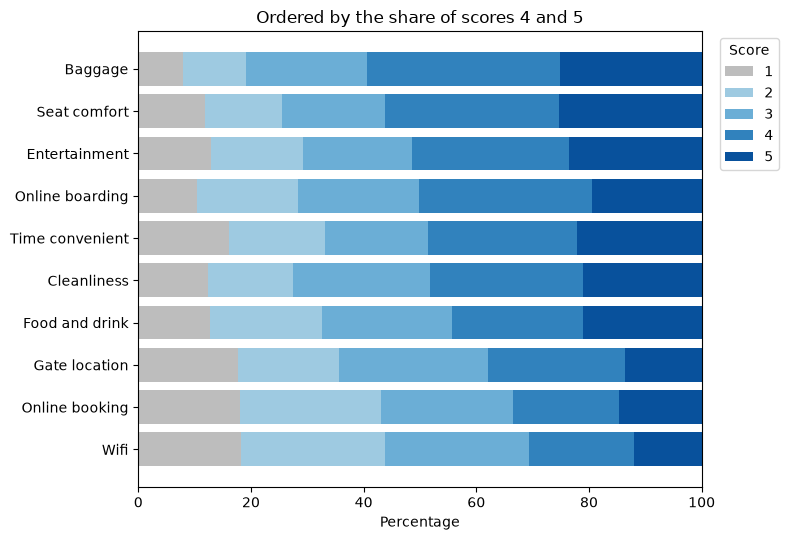

In [6]:
# Same percentages. Bars are ordered by the combined share of scores 4 and 5, largest first.
ranked = table.copy()
ranked["high"] = ranked[4] + ranked[5]
ranked = ranked.sort_values("high", ascending=False).drop(columns="high")

fig, ax = plt.subplots(figsize=(8, 5.5))
left = pd.Series(0.0, index=ranked.index)
for score, color in zip(scores, colors):
    ax.barh(ranked.index, ranked[score], left=left, color=color, label=str(score))
    left = left + ranked[score]
ax.invert_yaxis()
ax.set_xlabel("Percentage")
ax.set_xlim(0, 100)
ax.legend(title="Score", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("Ordered by the share of scores 4 and 5")
plt.tight_layout()
plt.show()


The second chart uses the same percentages. Its bars are ordered by the combined share of scores 4 and 5, from the largest to the smallest.

Passengers are relatively satisfied with baggage handling, seat comfort, and entertainment. On the contrast, Wifi, online booking, and gate location are the least satisfactory. Managers may put more resources on improving passengers' experience on Wifi, online booking, and gate location.


### 1.3.2 Departure delay, arrival delay, and flight distance by satisfaction


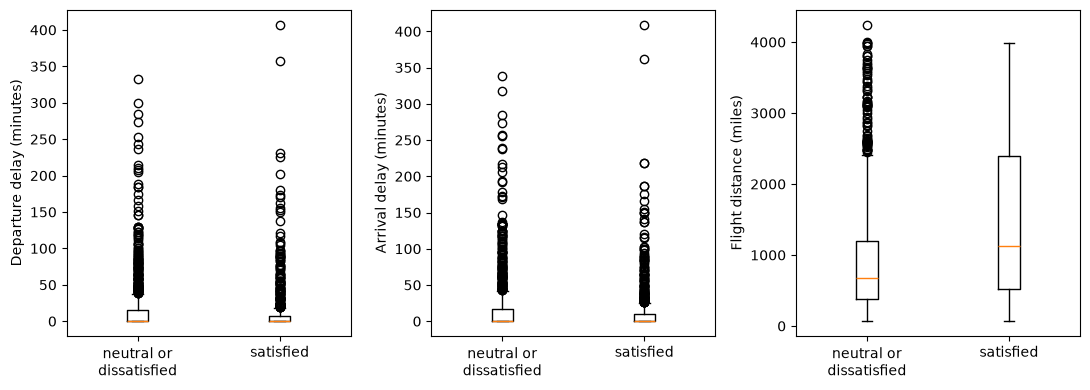

In [7]:
# Boxplots by satisfaction. Missing values are left out of each group.
# The three variables use different units, so each has its own panel.
satisfaction_order = ["neutral or dissatisfied", "satisfied"]
variables = [
    ("Departure Delay in Minutes", "Departure delay (minutes)"),
    ("Arrival Delay in Minutes", "Arrival delay (minutes)"),
    ("Flight Distance", "Flight distance (miles)"),
]

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, (column, ylabel) in zip(axes, variables):
    groups = [
        df.loc[df["satisfaction"] == label, column].dropna()
        for label in satisfaction_order
    ]
    ax.boxplot(groups)
    ax.set_xticklabels(["neutral or\ndissatisfied", "satisfied"])
    ax.set_ylabel(ylabel)
plt.tight_layout()
plt.show()


The median departure delay and the median arrival delay are both 0 minutes in each satisfaction group. The median flight distance is about 1,120 miles for satisfied passengers and about 674 miles for the others.


### Means after the outliers are removed

The boxplots above keep every observed value. A long delay pulls the mean up, so the bars below leave out the outliers already flagged in Part I. For each variable, a value is removed when it lies below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. 


In [8]:
# A copy, so the original data and the later scatter plot are unchanged.
# Outliers use the same Q1 - 1.5*IQR rule. A flagged value is set to missing in the copy.
compare_columns = [
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
    "Flight Distance",
]
cleaned = df.copy()
for column in compare_columns:
    values = cleaned[column]
    observed = values.dropna()
    q1 = observed.quantile(0.25)
    q3 = observed.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    is_outlier = values.notna() & ((values < lower) | (values > upper))
    cleaned.loc[is_outlier, column] = np.nan
    n_out = int(is_outlier.sum())
    n_remaining = int(cleaned[column].notna().sum())
    percentage = round(100 * n_out / (n_out + n_remaining), 1)
    print(column)
    print("  outliers removed:", n_out)
    print("  percentage:", percentage)
    print("  values remaining:", n_remaining)


Departure Delay in Minutes
  outliers removed: 270
  percentage: 13.9
  values remaining: 1673
Arrival Delay in Minutes
  outliers removed: 256
  percentage: 13.2
  values remaining: 1687
Flight Distance
  outliers removed: 60
  percentage: 3.1
  values remaining: 1890


### Interpretation:

More than 10% of the observed delay values are outliers, which indicates that the delay distribution is skewed. Removing those outliers changes the distribution being summarised.


Departure Delay in Minutes | neutral or dissatisfied | n = 894 | mean = 4.0
Departure Delay in Minutes | satisfied | n = 716 | mean = 3.0
Arrival Delay in Minutes | neutral or dissatisfied | n = 894 | mean = 4.8
Arrival Delay in Minutes | satisfied | n = 729 | mean = 3.9
Flight Distance | neutral or dissatisfied | n = 1043 | mean = 906.4
Flight Distance | satisfied | n = 775 | mean = 1362.3


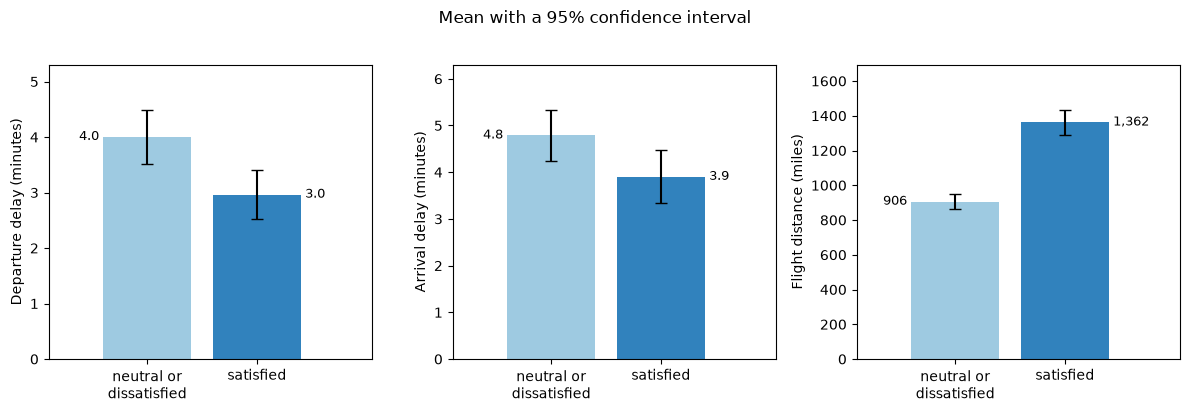

In [9]:
labels = ["neutral or\ndissatisfied", "satisfied"]
satisfaction_order = ["neutral or dissatisfied", "satisfied"]
variables = [
    ("Departure Delay in Minutes", "Departure delay (minutes)"),
    ("Arrival Delay in Minutes", "Arrival delay (minutes)"),
    ("Flight Distance", "Flight distance (miles)"),
]

# Bars are means after the outliers were removed.
# sigma is unknown, so each whisker is the half-width of a 95% t interval for the mean.
# The number is printed beside the top of the bar, level with the mean.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
x = np.arange(len(satisfaction_order))
for ax, (column, ylabel) in zip(axes, variables):
    means = []
    errors = []
    for label in satisfaction_order:
        group = cleaned.loc[cleaned["satisfaction"] == label, column].dropna()
        n = len(group)
        mean = group.mean()
        half = stats.t.ppf(0.975, n - 1) * group.std(ddof=1) / np.sqrt(n)
        means.append(mean)
        errors.append(half)
        print(column, "|", label, "| n =", n, "| mean =", round(mean, 1))
    bars = ax.bar(x, means, yerr=errors, capsize=4, color=["#9ecae1", "#3182bd"])
    top = max(mean + error for mean, error in zip(means, errors))
    ax.set_ylim(0, top * 1.18)
    ax.set_xlim(-0.9, 2.05)
    for bar, mean, side in zip(bars, means, [-1, 1]):
        if "Distance" in column:
            text = f"{mean:,.0f}"
        else:
            text = f"{mean:.1f}"
        if side < 0:
            x_text = bar.get_x() - 0.04
            ha = "right"
        else:
            x_text = bar.get_x() + bar.get_width() + 0.04
            ha = "left"
        ax.text(x_text, mean, text, ha=ha, va="center", fontsize=9, color="black", clip_on=False)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)
fig.suptitle("Mean with a 95% confidence interval", y=1.02)
plt.tight_layout()
plt.show()


### Interpretation:

The bars are sample means after the outliers are removed. They are flights with delays below the Tukey fence. The whiskers are 95% confidence intervals for the mean. They are not the whiskers from a boxplot. A boxplot whisker describes the spread of the observations. These whiskers describe how precisely the mean is estimated.

In satisfied group, the average departure delay and average arrival delay are both shorter. Also, on average, compared to the neutral or dissatisfied passengers, satisfied passengers have longer flight distance.


### 1.3.3 Departure delay and arrival delay


rows used: 1888
correlation: 0.961


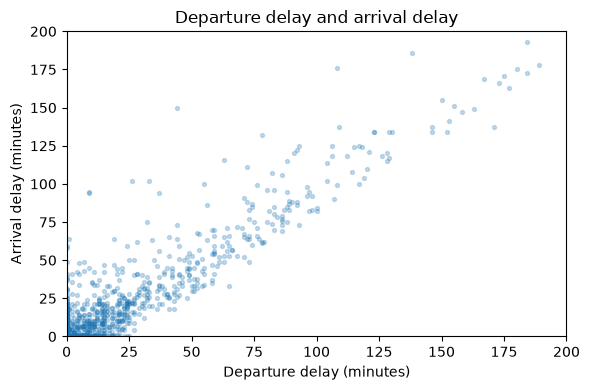

In [10]:
# Passengers who have both a departure delay and an arrival delay.
complete = df.dropna(subset=["Departure Delay in Minutes", "Arrival Delay in Minutes"])
r = complete["Departure Delay in Minutes"].corr(complete["Arrival Delay in Minutes"])
print("rows used:", len(complete))
print("correlation:", round(r, 3))

# Axes stop at 200 minutes so the main cloud of points is visible.
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(
    complete["Departure Delay in Minutes"],
    complete["Arrival Delay in Minutes"],
    s=8,
    alpha=0.25,
)
ax.set_xlim(0, 200)
ax.set_ylim(0, 200)
ax.set_xlabel("Departure delay (minutes)")
ax.set_ylabel("Arrival delay (minutes)")
ax.set_title("Departure delay and arrival delay")
plt.tight_layout()
plt.show()


### Interpretation:

The correlation is about 0.96. Departure delay and arrival delay have a strong positive association: a flight that leaves later tends to arrive later.

## 2 Research questions

### 2.1 Three Research questions proposed by the author:

#### 2.1.1 Average service score for loyal and disloyal customers

Is the mean average_service_score the same for loyal customers and disloyal customers?

The question matters because loyal passengers are the ones the airline keeps. If their average service score is lower, the retained customers are reporting a worse service experience. If the two means are the same, the service score does not separate passengers who stay from passengers who do not.

#### 2.1.2 Satisfaction in Business and Eco

Is the proportion of satisfied passengers the same in Business and in Eco?

This question matters because Business and Eco represent different price and service offerings. If Business passengers are no more likely to be satisfied than Eco passengers, the premium offering is not associated with a higher satisfaction rate, which warrants reviewing whether it meets passengers’ expectations. If Eco passengers are less likely to be satisfied, managers should investigate the service issues contributing to that gap and identify opportunities to improve the Eco experience.

#### 2.1.3 Which characteristics are associated with being satisfied

How is the probability of being satisfied related to gender, customer type, age, type of travel, class, flight distance, total_rating_score, and departure delay in minutes?

The question matters because delay, cabin, and service ratings occur together, so a gap in one of them may belong to another. The logistic regression shows which characteristic is still associated with the probability of being satisfied when the others are held fixed. A negative coefficient on departure delay, for example, would mean that a longer delay is still tied to a lower chance of being satisfied after class, total_rating_score are taken into account, so the delay itself remains a reason for the airline to act.


### 2.2 Research Questions Proposed by AI:

#### <span style="color:red">Prompt:</span> paste your prompt to generate the following questions here.


#### 2.2.1 How late do passengers arrive, on average?

Estimate the population mean of arrival delay with a 95% $t$ interval. 

#### 2.2.2 What share of passengers leave late?

Estimate the population proportion with a departure delay greater than 0 minutes, using a 95% $z$ interval. 
#### 2.2.3 How common is a poor wifi rating?

Among passengers whose inflight wifi score is 1 to 5, estimate the proportion who give 1 or 2, again with a 95% $z$ interval. 

### <span style="color:red">Final research questions with reasons:</span> 


### Research question 1

- Null and alternative hypothesis
- Test and test statistics formula and why this test is appropriate
- Python code cell to implement the test
- Results
- Business interpretation

### Research question 2

### Research question 3

## Part III Human–AI Partnership Reflective Essay 

## Reference
